# Feature Importance Analyses for Mislocalized Variants

We select for the interpretable CellProfiler features that contribute most significantly in the XGBoost Classifier to help distinguish the mislocalized variants from their respective reference alleles.

In [14]:
import os
import random
import operator
from tqdm import tqdm
import polars as pl
import seaborn as sns
from adjustText import adjust_text
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from functools import reduce
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_distances
import networkx as nx
import community.community_louvain as community_louvain
import umap

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *
from utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

# controls = {
#     "TC": ["EGFP"],
#     "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
#     "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
#     # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
#     # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
#     # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
#     # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
# }
# ctrl_alleles = [k_v for k_v in controls.values()]
# ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
# # ctrl_alleles_flat

## classification results in SM pipeline
SM_CLASS_RES_DIR = CLASS_RESULTS_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells"
FEAT = "GFP"
MISLOCALIZED_LABEL = "Altered_95th_perc_both_batches_GFP"

## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

np.random.seed(42)
random.seed(42)

## 1. Load feature importance and classifier info

In [2]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

### 1.1 Feature importance for each variant

In [3]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col(MISLOCALIZED_LABEL)==1
)
print("Number of hits:", imaging_summary_clinvar_hits.shape[0])
allele_list = list(imaging_summary_clinvar["gene_allele"]) + list(imaging_summary_clinvar["Gene"].unique())
hits_allele_list = list(imaging_summary_clinvar_hits["gene_allele"]) + list(imaging_summary_clinvar_hits["Gene"].unique())
bio_reps = list(imaging_summary_clinvar_hits["Metadata_Bio_Batch"].unique())

Number of hits: 233


In [41]:
imaging_summary_clinvar.shape

(943, 566)

In [5]:
# feat_import_df_feat = pl.DataFrame()
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         # Read the data
#         feat_df = pl.scan_csv(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id)}/feat_importance.csv")
#         meta_cols = [c for c in feat_df.collect_schema().names() if c.startswith("Metadata_") or c.startswith("Group") or c == "Batch"]
#         feat_cols = [c for c in feat_df.collect_schema().names() if c not in meta_cols and FEAT in c]
#         feat_df_batch = feat_df.with_columns(
#             [pl.col(c).cast(pl.Float64, strict=False).alias(c) for c in feat_cols]
#         ).with_columns(
#             pl.lit(batch_id).alias("Metadata_Batch"),
#             pl.col("Group2").str.split('_').list.slice(-2).list.join("_").alias("Metadata_gene_allele")
#        ).filter(
#             (pl.col("Metadata_Feature_Type")==FEAT)&(~pl.col("Metadata_Control"))
#             &(pl.col("Group1").is_in(allele_list)|(pl.col("Metadata_gene_allele").is_in(batch_allele_list)))
#         ).select(meta_cols + feat_cols + ["Metadata_Batch", "Metadata_gene_allele"])
#         feat_import_df_feat = pl.concat([feat_import_df_feat, feat_df_batch.collect()], how="diagonal")

In [6]:
# key_alleles_df = imaging_summary_clinvar.to_pandas()
# feat_df = pl.DataFrame()
# importance_thres = 1e-3
# # top_num = 5

# for j, allele in tqdm(key_alleles_df.iterrows()):
#     batch_list = list(feat_import_df_feat.filter(
#         pl.col("Metadata_gene_allele")==allele["gene_allele"]
#     ).unique("Metadata_Batch")["Metadata_Batch"])
#     allele_df = pl.DataFrame()
#     for i, batch in enumerate(batch_list):
#         batch_df = feat_import_df_feat.filter(
#             (pl.col("Metadata_Batch")==batch)&(pl.col("Metadata_gene_allele")==allele["gene_allele"])
#         )
#         feat_cols = [col for col in batch_df.columns if "Metadata" not in col and "Group" not in col]
#         batch_df = batch_df.filter(
#             ~pl.all_horizontal(pl.col(feat_cols).is_null())
#         )
#         non_null_gfp = [col for col in feat_cols if not batch_df[col].is_null().any()]
#         batch_df_col = (
#             batch_df.select(non_null_gfp).mean()
#            .transpose(include_header=True)
#            .filter(pl.col("column_0") > importance_thres)
#            .sort("column_0", descending=True)
#            # .head(top_num)#["column"]
#            # .to_list()
#         )
#         if not allele_df.is_empty():
#             allele_df = allele_df.join(
#                 batch_df_col.with_columns(
#                     pl.col("column_0").alias(batch),
#                     pl.col("column").alias("index"),
#                 ).select("index", batch),
#                 on="index",
#                 how="full",
#                 coalesce=True
#             )
#         else:
#             allele_df = batch_df_col.with_columns(
#                 pl.col("column_0").alias(batch),
#                 pl.col("column").alias("index"),
#             ).select("index", batch)
            
#     allele_df = allele_df.with_columns(
#         pl.mean_horizontal(pl.col([col for col in allele_df.columns if "Batch" in col])).alias("feat_importance"),
#         pl.col("index").alias("cp_feature")
#     ).select(
#         pl.col(["cp_feature", "feat_importance"])
#     ).rename(
#         {"feat_importance": allele["gene_allele"]}
#     )
#     if not feat_df.is_empty():
#         feat_df = feat_df.join(
#             allele_df,
#             left_on="cp_feature",
#             right_on="cp_feature",
#             how="full",
#             coalesce=True
#         )
#     else:
#         feat_df = allele_df

915it [02:45,  5.54it/s]


In [8]:
# feat_df.write_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

### 1.2 Load CellProfiler features

#### 1.2.1 Load the features from the valid cells only

In [4]:
# Paths
ref_var_cell_qc_prof_df = pl.DataFrame()
target_gene_alleles = []
meta_cols = [
    "Metadata_CellID",
    "Metadata_gene_allele",
    "Metadata_Well",
    "Metadata_Plate",
    "Metadata_node_type"
]

# Get meta features
for bio_rep in bio_reps:
    bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
    ## ONLY grep the allele come from the bio-rep
    allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
    batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
    for batch_id in bio_rep_batches:
        batch_alleles = (
            pl.scan_parquet(
                PASS_QC_PROF_PQ.format(batch_id=batch_id)
            )
            .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
            .with_columns(
                pl.concat_str(
                    [
                        "Metadata_Plate",
                        "Metadata_Well",
                        "Metadata_ImageNumber",
                        "Metadata_ObjectNumber",
                    ],
                    separator="_",
                ).alias("Metadata_CellID")
            )
        ).collect()
        # feat_cols = [col for col in batch_alleles.columns if ("AGP".lower() in col.lower() or "DNA".lower() in col.lower() or "Mito".lower() in col.lower()) and ("GFP".lower() not in col.lower())]
        batch_alleles = batch_alleles.join(
            img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==FEAT).select(pl.col("plate", "well", "is_bg")),
            left_on=["Metadata_Plate", "Metadata_Well"],
            right_on=["plate", "well"]
        ).filter(
            ~pl.col("is_bg")
        ).select(pl.col(meta_cols))
        ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

#### 1.2.2 Load all the features available

In [6]:
# Paths
ref_var_cell_all_prof_list = []
for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    ## ONLY grep the allele come from the bio-rep
    allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
    batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
    for batch_id in bio_rep_batches:
        batch_alleles = (
            pl.scan_parquet(
                ALL_PROF_QC.format(batch_id=batch_id)
            )
            .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
            .with_columns(
                pl.concat_str(
                    [
                        "Metadata_Plate",
                        "Metadata_Well",
                        "Metadata_ImageNumber",
                        "Metadata_ObjectNumber",
                    ],
                    separator="_",
                ).alias("Metadata_CellID")
            )
        )
        ref_var_cell_all_prof_list.append(batch_alleles)

all_feat_cols = reduce(
    set.intersection, 
    map(set, [[col for col in ref_var_cell_all_prof.collect_schema() \
               if (FEAT.lower() in col.lower()) and ("Brightfield".lower() not in col.lower())] 
               for ref_var_cell_all_prof in ref_var_cell_all_prof_list])
)

select_cols = list(all_feat_cols) + ["Metadata_CellID"]
ref_var_cell_all_prof_df = pl.concat([
    batch_alleles.select(select_cols).collect() for batch_alleles in ref_var_cell_all_prof_list
])

# This method of joining ensures that only cells past filters are included in the abundance analysis
ref_var_cell_all_prof_df = ref_var_cell_qc_prof_df.join(ref_var_cell_all_prof_df, 
                                                        on="Metadata_CellID", 
                                                        how="left", coalesce=True)

In [7]:
ref_var_cell_all_prof_df.shape

(2856956, 449)

In [8]:
# ref_var_cell_all_prof_df.write_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc.parquet")

## 2. Single-cell CP profile preprocessing

In [10]:
ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc.parquet")
ref_var_cell_all_prof_df.shape

(2856956, 449)

In [42]:
ref_var_cell_all_prof_df.unique("Metadata_gene_allele")

Metadata_CellID,Metadata_gene_allele,Metadata_Well,Metadata_Plate,Metadata_node_type,Cells_Texture_DifferenceEntropy_GFP_20_02_256,Cells_Texture_Correlation_GFP_20_03_256,Nuclei_Correlation_Correlation_GFP_Mito,Cells_RadialDistribution_MeanFrac_GFP_4of10,Cytoplasm_Texture_SumEntropy_GFP_20_00_256,Cells_Texture_DifferenceEntropy_GFP_5_03_256,Cells_Location_MaxIntensity_Y_GFP,Cells_Texture_InverseDifferenceMoment_GFP_20_03_256,Cells_Granularity_3_GFP,Cytoplasm_Texture_SumEntropy_GFP_5_03_256,Cells_Texture_InverseDifferenceMoment_GFP_10_03_256,Nuclei_Texture_SumAverage_GFP_20_01_256,Cells_Texture_SumEntropy_GFP_10_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_20_00_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_03_256,Cells_RadialDistribution_FracAtD_GFP_6of10,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_03_256,Cells_Texture_AngularSecondMoment_GFP_5_00_256,Cells_Intensity_UpperQuartileIntensity_GFP,Cytoplasm_Texture_Entropy_GFP_20_01_256,Cytoplasm_RadialDistribution_FracAtD_GFP_10of10,Cells_Texture_Correlation_GFP_20_02_256,Nuclei_RadialDistribution_MeanFrac_GFP_7of10,Cells_Texture_Entropy_GFP_10_00_256,Nuclei_Texture_AngularSecondMoment_GFP_5_03_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cytoplasm_Granularity_2_GFP,Nuclei_Texture_DifferenceVariance_GFP_5_00_256,Cells_Texture_DifferenceVariance_GFP_20_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_10_00_256,Nuclei_Texture_DifferenceVariance_GFP_20_01_256,Cells_Texture_DifferenceVariance_GFP_5_02_256,…,Cells_Correlation_RWC_AGP_GFP,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cytoplasm_Texture_InfoMeas2_GFP_10_03_256,Cells_RadialDistribution_RadialCV_GFP_9of10,Nuclei_Correlation_RWC_DNA_GFP,Cells_Texture_InfoMeas1_GFP_20_00_256,Cells_Location_MaxIntensity_X_GFP,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_02_256,Cells_Texture_DifferenceEntropy_GFP_20_00_256,Cells_Texture_InfoMeas1_GFP_20_03_256,Cytoplasm_Texture_SumEntropy_GFP_5_02_256,Cells_Texture_AngularSecondMoment_GFP_10_00_256,Cells_Texture_AngularSecondMoment_GFP_5_01_256,Cytoplasm_RadialDistribution_RadialCV_GFP_2of10,Cells_Intensity_MeanIntensity_GFP,Cells_Texture_DifferenceEntropy_GFP_10_01_256,Nuclei_RadialDistribution_RadialCV_GFP_6of10,Nuclei_Intensity_MaxIntensity_GFP,Nuclei_RadialDistribution_RadialCV_GFP_1of10,Cytoplasm_Granularity_7_GFP,Cytoplasm_Correlation_RWC_DNA_GFP,Nuclei_Texture_Correlation_GFP_5_01_256,Nuclei_Texture_DifferenceVariance_GFP_20_00_256,Cells_Texture_InfoMeas1_GFP_5_00_256,Cells_Intensity_LowerQuartileIntensity_GFP,Nuclei_Texture_DifferenceVariance_GFP_20_02_256,Nuclei_Correlation_RWC_GFP_Mito,Cytoplasm_Texture_DifferenceVariance_GFP_20_03_256,Nuclei_Texture_InverseDifferenceMoment_GFP_5_03_256,Cytoplasm_Texture_InfoMeas2_GFP_5_00_256,Cells_Location_CenterMassIntensity_X_GFP,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_Texture_InfoMeas1_GFP_20_01_256,Cytoplasm_RadialDistribution_RadialCV_GFP_6of10,Metadata_hpa_main_loc,Metadata_hpa_approved,Metadata_final_loc
str,str,str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,str,str,str
"""2024_01_17_B7A1R1_P2T1_D10_735…","""KRT8_Gly53Val""","""D10""","""2024_01_17_B7A1R1_P2T1""","""allele""",2.955272,1.711398,0.48246,-4.595351,4.520566,3.563464,-0.703008,-1.480706,2.64756,5.157446,-2.323011,-1.087461,3.602966,-0.886262,-3.064048,-1.068617,-1.55082,-0.898115,5.34466,6.011061,2.100577,-0.353605,-6.011571,4.66799,-0.586128,-1.740743,14.411551,-0.557814,-0.880209,-0.895657,-1.0,-0.902946,…,-3.334809,-0.247179,5.122276,0.923905,-2.151303,-4.645257,1.878676,-2.872761,2.990801,-8.331902,5.284689,-0.88574,-0.841965,1.075168,4.560467,2.671846,3.368254,3.151158,0.525928,4.836146,-2.192158,3.066637,-1.0,-0.493872,3.093031,-1.0,-0.659063,-0.892821,-1.411982,1.886527,1.845835,3.444933,-4.599166,2.570567,null,null,

### 2.1 Attach Gene Loc info

In [11]:
gene_loc_df = pl.read_csv("../../1_inputs/subcell_loc/hpa_subcellular_location_annotations/subcellular_location_data.tsv", separator="\t", infer_schema_length=10000000)
gene_loc_opencell_df = pl.read_csv("../../1_inputs/subcell_loc/opencell_subcellular_location_annot/opencell-localization-annotations.csv", infer_schema_length=10000000)
gene_loc_all_df = gene_loc_df.select(
    pl.col(["Gene", "Gene name", "Main location", "Approved", "GO id"])
).join(
    gene_loc_opencell_df,
    left_on=["Gene name", "Gene"],
    right_on=["target_name", "ensg_id"],
    how="full",
    coalesce=True
).with_columns(
    pl.when(pl.col("Approved").is_not_null())
    .then(pl.col("Approved"))
    .when((pl.col("Approved").is_null())&(pl.col("annotations_grade_3").is_not_null()))
    .then(pl.col("annotations_grade_3"))
    .otherwise(pl.lit("Uncertain"))
    .alias("Approved_Final_Loc")
)

In [12]:
ref_var_cell_all_prof_df = ref_var_cell_all_prof_df.join(
    gene_loc_all_df.select(
        pl.col(["Gene name", "Main location", "Approved", "Approved_Final_Loc"])
    ).rename(
        {
            "Main location": "Metadata_hpa_main_loc",
            "Approved": "Metadata_hpa_approved",
            "Approved_Final_Loc": "Metadata_final_loc"
        }
    ),
    left_on="Metadata_gene_allele",
    right_on="Gene name",
    how="left"
)

### 2.2 INT Normalization

In [15]:
# Extract features once
feature_cols = [c for c in ref_var_cell_all_prof_df.columns if "Metadata" not in c]
# features = ref_var_cell_all_prof_df.select(pl.col(feature_cols))

# Standardize by INT and fit PCA
data_scaled = inverse_normal_transform(ref_var_cell_all_prof_df, feature_cols)

  0%|          | 0/444 [00:00<?, ?it/s]

### 2.3 Feature selection

In [20]:
from pycytominer.feature_select import feature_select

data_scaled = feature_select(data_scaled.to_pandas(), operation="variance_threshold")
data_scaled = feature_select(data_scaled, operation="correlation_threshold")
data_scaled.shape

(2856956, 150)

In [22]:
data_scaled_pl = pl.DataFrame(data_scaled)

In [23]:
data_scaled_pl.write_parquet(
    "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc_int_featselect.parquet"
)

## 3. Data Exploration

### 3.1 Dimension reduction

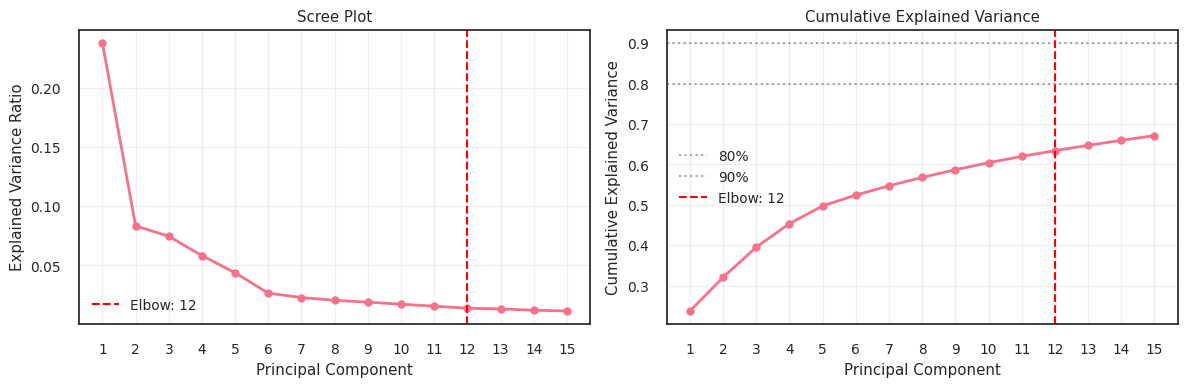

Optimal components: 12
Explained variance at elbow: 63.4%


In [25]:
pca = PCA()  # Get top 10 PCs
pca_components = pca.fit_transform(data_scaled_pl.select(
    [c for c in data_scaled_pl.columns if "Metadata_" not in c]
).to_numpy())

# Calculate variances
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

from kneed import KneeLocator
# Find elbow point using KneeLocator
knee_locator = KneeLocator(
    range(1, len(explained_variance_ratio)+1),
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)
optimal_components = knee_locator.knee


# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
# Scree plot
n_show = min(15, len(explained_variance_ratio))
ax1.plot(range(1, n_show + 1), explained_variance_ratio[:n_show], 'o-', linewidth=2)
ax1.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot')
ax1.set_xticks(range(1, n_show + 1))
ax1.legend()
ax1.grid(True, alpha=0.3)

# Cumulative variance plot
ax2.plot(range(1, n_show + 1), cumulative_variance[:n_show], 'o-', linewidth=2)
ax2.axhline(y=0.8, color='gray', linestyle=':', alpha=0.7, label='80%')
ax2.axhline(y=0.9, color='gray', linestyle=':', alpha=0.7, label='90%')
ax2.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Cumulative Explained Variance')
ax2.set_title('Cumulative Explained Variance')
ax2.set_xticks(range(1, n_show + 1))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Results
print(f"Optimal components: {optimal_components}")
print(f"Explained variance at elbow: {cumulative_variance[optimal_components-1]:.1%}")

In [27]:
# # Apply optimal PCA
# pca = PCA(n_components=optimal_components)
# pca_components = pca.fit_transform(
#     data_scaled_pl.select(
#     [c for c in data_scaled_pl.columns if "Metadata_" not in c]
# ).to_numpy())

# # UMAP on top 10 PCs
# umap_reducer = umap.UMAP(n_components=2, random_state=42)
# umap_embedding = umap_reducer.fit_transform(pca_components)

In [28]:
# Create result dataframe
# data_results = pd.DataFrame({
#    'PC1': pca_components[:, 0],
#    'PC2': pca_components[:, 1],
#    'UMAP1': umap_embedding[:, 0],
#    'UMAP2': umap_embedding[:, 1],
#    'Metadata_CellID': ref_var_cell_all_prof_df["Metadata_CellID"],
#    'Metadata_Batch': ref_var_cell_all_prof_df["Metadata_Plate"].str.extract(r'B(\d+)A'),
#    'Metadata_final_loc': ref_var_cell_all_prof_df["Metadata_final_loc"],
#    'Metadata_gene_allele': ref_var_cell_all_prof_df["Metadata_gene_allele"]
# })
# data_results.to_parquet(
#     "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc_dr_embeddings.parquet"
# )

In [32]:
data_results_pl = pl.read_parquet(
    "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc_dr_embeddings.parquet"
)
data_results = data_results_pl.to_pandas()

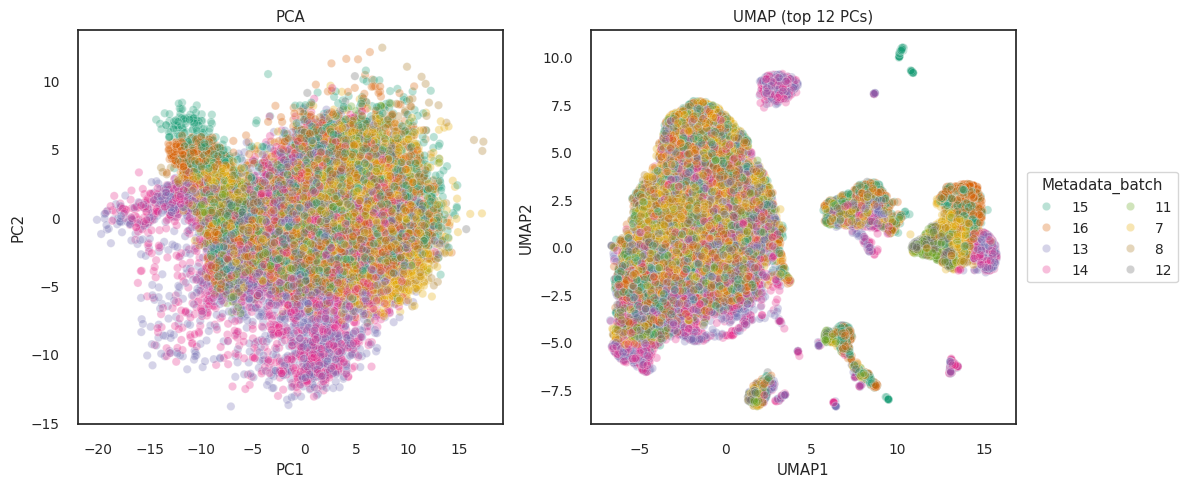

In [38]:
# Plot side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=data_results.sample(frac=0.01, random_state=0),
    x="PC1",
    y="PC2",
    hue="Metadata_Batch",
    palette="Dark2",
    ax=ax1,
    alpha=.3
)
ax1.set_title('PCA')
ax1.get_legend().remove()

# UMAP plot
sns.scatterplot(
    data=data_results.sample(frac=0.01, random_state=0),
    x="UMAP1",
    y="UMAP2",
    hue="Metadata_Batch",
    palette="Dark2",
    ax=ax2,
    alpha=.3
)
ax2.set_title(f'UMAP (top {optimal_components} PCs)')
ax2.legend(bbox_to_anchor=(1.01, 0.5), loc='center left', 
           frameon=True, title="Metadata_batch", ncol=2)
plt.tight_layout()
plt.show()

In [40]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Calculate variance explained by batch
X = pd.get_dummies(data_results['Metadata_Batch'])
y = data_results['PC1']
model = LinearRegression().fit(X, y)
batch_r2 = r2_score(y, model.predict(X))
print(f"Batch explains {batch_r2:.1%} of PC1 variance")

Batch explains 2.3% of PC1 variance
